In [2]:
import numpy as np

In [3]:
x = np.zeros(20)
y = np.zeros(20)
y[-1] = 0
x[-1] = 0
x[0] = 1
x[1] = -1
print(x)
for n in range(0,4):
    y[n] = -0.5*y[n-1]+x[n]+2*x[n-1]
print(y[0:4])

[ 1. -1.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.
  0.  0.]
[ 1.     0.5   -2.25   1.125]


In [4]:
from scipy import signal 
x=np.array([1,-1,0,0],dtype=float)
b=[1,2]
a=[1,0.5]
y=signal.lfilter(b,a,x)
print(y)

[ 1.     0.5   -2.25   1.125]


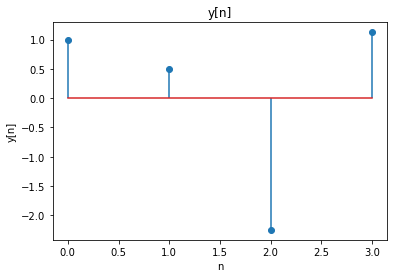

In [5]:
from matplotlib import pyplot as plt
n=np.arange(0,4)
plt.stem(n,y)
plt.title('y[n]')
plt.xlabel('n')
plt.ylabel('y[n]')
plt.show()

In [6]:
import numpy as np
x=np.array([1,2,-1],dtype=float)
h=np.array([1,3],dtype=float)
nXmin = 0
nHmin = 0
M = len(x)
N = len(h)
L = M + N -1
y=np.zeros(L)
for n in range(L):
    y[n]=0
    for k in range(M):
        if (n-k)>=0 and (n-k)<N:
            y[n]=y[n]+x[k]*h[n-k]
print(y)

[ 1.  5.  5. -3.]


In [7]:
nY = [i for i in range(nXmin+nHmin,nXmin+nHmin+L)] 
print(nY)

[0, 1, 2, 3]


In [8]:
x=np.array([1,0,2,-1],dtype=float)
h=np.array([1,0,0,0,3],dtype=float)
nXmin = -1
nHmin = -2
M = len(x)
N = len(h)
L = M + N -1
y=np.zeros(L)
for n in range(L):
    y[n]=0
    for k in range(M):
        if (n-k)>=0 and (n-k)<N:
            y[n]=y[n]+x[k]*h[n-k]
print(y)

[ 1.  0.  2. -1.  3.  0.  6. -3.]


In [9]:
nY = [i for i in range(nXmin+nHmin,nXmin+nHmin+L)] 
print(nY)

[-3, -2, -1, 0, 1, 2, 3, 4]


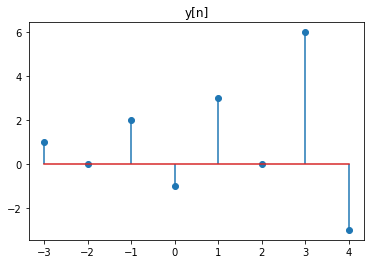

In [10]:
plt.stem(nY,y) 
plt.title('y[n]')
plt.show()

In [11]:
x=np.array([1,2,-1],dtype=float) 
h=np.array([1,3],dtype=float) 
print(np.convolve(x,h)) 
print(signal.convolve(x,h))

[ 1.  5.  5. -3.]
[ 1.  5.  5. -3.]


# ÖDEV 2

# SORU1
𝑦[𝑛] − 𝟏. 𝟐𝑦[𝑛 − 1] = 𝑥[𝑛] − 𝑥[𝑛 − 4] fark denklemiyle ifade edilen DZD bir sistem için aşağıda verilen soruları cevaplayınız.<br>
### a) 
Bu sistemin girişine 𝑥[𝑛] = 𝑢[𝑛 − 3] işaretini uygulayın. Bunun için önce 𝑥[𝑛]′i n=0,1,...10 aralığı için üretip Scipy.signal kütüphanesinin convolve() fonksiyonuna ve aynı kütüphanenin lfilter() fonksiyonuna uygulayıp çıkış işaretini elde edip çizdirin (indislere dikkat edilmelidir). convolve() fonksiyonunu kullanırken üçüncü parametre olarak ‘same’ girildiğinde giriş ve çıkış işaretlerinin boyları aynı olur.


[0 0 0 1 1 1 1 1 1 1 1]
[ 0.         0.         0.         1.         2.2        3.64
  5.368      6.4416     7.72992    9.275904  11.1310848]


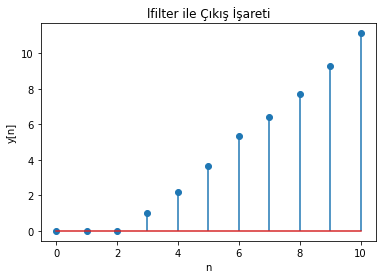

In [17]:
import numpy as np
#𝑦[𝑛] − 1.2𝑦[𝑛 − 1] = 𝑥[𝑛] − 𝑥[𝑛 − 4]
n = np.arange(0,11)
x =  np.where(n >= 3, 1, 0)
print(x)
b=[1,0,0,0,-1]
a=[1,-1.2]
y=signal.lfilter(b,a,x)
print(y)
plt.stem(n, y)
plt.title('lfilter ile Çıkış İşareti')
plt.xlabel('n')
plt.ylabel('y[n]')
plt.show()

[0 0 0 1 1 1 1 1 1 1 1]
[1.         1.2        1.44       1.728      1.0736     1.28832
 1.545984   1.8551808  2.22621696 2.67146035 3.20575242]


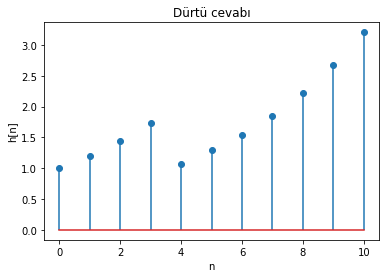

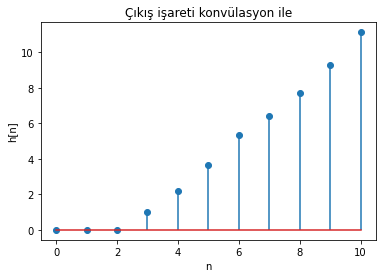

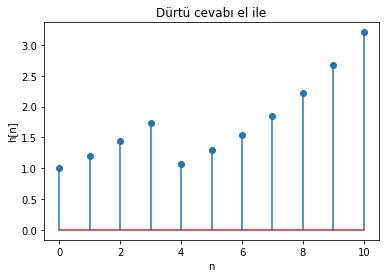

In [37]:
#𝑦[𝑛] − 1.2𝑦[𝑛 − 1] = 𝑥[𝑛] − 𝑥[𝑛 − 4]
def u(n):
    return np.where(n >= 0, 1, 0)
def delta(n):
    return np.where(n == 0, 1, 0)
n = np.arange(0,11)
xdirac =  delta(n)
print(x)
b=[1,0,0,0,-1]
a=[1,-1.2]
hn=signal.lfilter(b,a,xdirac)
print(hn)
plt.figure()
plt.stem(n, hn)
plt.title('Dürtü cevabı')
plt.xlabel('n')
plt.ylabel('h[n]')
plt.show()
plt.figure()
xn =  np.where(n >= 3, 1, 0)
yn = signal.convolve(hn, xn,mode = "full")[0:len(n)]
plt.stem(n, yn)
plt.title('Çıkış işareti konvülasyon ile')
plt.xlabel('n')
plt.ylabel('h[n]')
plt.show()

hn = (1.2**n) * u(n) - (1.2**(n-4)) * u(n-4)
plt.figure()
plt.stem(n, hn)
plt.title('Dürtü cevabı el ile')
plt.xlabel('n')
plt.ylabel('h[n]')
plt.show()



## Soru 2

SORU-2 (45 PUAN): Aşağıdaki sisteme (a), (b) ve (c) şıklarında verilen giriş işaretleri uygulandığında bu sistemin çıkışında elde edilecek işaretleri bulunuz. Hem giriş işaretinin hem de çıkış işaretinin grafiklerini çizdiriniz. Not: Toplam 3 çıkış işareti elde edeceksiniz.<br>
SİSTEM-2: h2[𝑛] = 𝛿[𝑛 − 3] − 𝛿[𝑛 − 4]) <br>
a) 𝑥3[𝑛] = cos ((𝜋/5) 𝑛) (𝑢[𝑛] − 𝑢[𝑛 − 20])<br>
b) 𝑥4[𝑛] = (−0.3)𝑛(𝑢[𝑛 − 1] − 𝑢[𝑛 − 5])<br>
c) 𝑥5[𝑛] = 𝑛 ∗ 𝑢[𝑛]

### a)

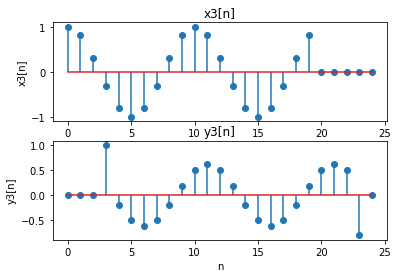

In [20]:
n = np.arange(0,25)


def u(n):
    return np.where(n >= 0, 1, 0)
def delta(n):
    return np.where(n == 0, 1, 0)
h2n = np.array([0, 0, 0, 1, -1])
#print(h2n)
x3n = np.cos((np.pi / 5)*n) *(u(n) - u(n-20))
#print(x3n)
y3n = signal.convolve(x3n,h2n,"full")[0:len(n)]
#print(y3n)
#plot x3n and y3n with subplot
plt.subplot(2, 1, 1)
plt.stem(n, x3n)
plt.title('x3[n]')
plt.xlabel('n')
plt.ylabel('x3[n]')
plt.subplot(2, 1, 2)
plt.stem(n, y3n)
plt.title('y3[n]')
plt.xlabel('n')
plt.ylabel('y3[n]')
plt.show()

### b)

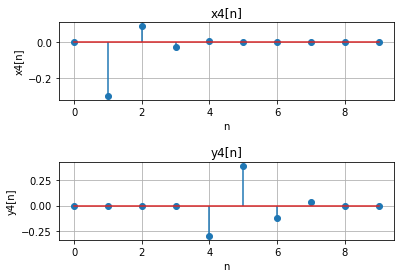

In [19]:
def u(n):
    return np.where(n >= 0, 1, 0)
def delta(n):
    return np.where(n == 0, 1, 0)

n = np.arange(0,10)
h2n = np.array([0, 0, 0, 1, -1])
#print(h2n)
x4n = (-0.3)**n *(u(n-1) - u(n-5))
#print(x4n)
y4n = signal.convolve( x4n,h2n,mode = "full")[0:len(n)]
#print(y4n)
#plot x4n and y4n with subplot
plt.subplot(2, 1, 1)
plt.stem(n, x4n)
plt.title('x4[n]')
plt.xlabel('n')
plt.ylabel('x4[n]')
plt.subplots_adjust(hspace=0.8)
plt.grid()
plt.subplot(2, 1, 2)
plt.stem(y4n)
plt.title('y4[n]')
plt.xlabel('n')
plt.ylabel('y4[n]')
plt.grid()
plt.show()


### c)

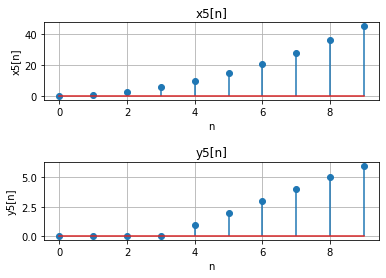

6


In [35]:
def u(n):
    return np.where(n >= 0, 1, 0)
def delta(n):
    return np.where(n == 0, 1, 0)

n = np.arange(0,10)
h2n = delta(n-3) - delta(n-4)
x5n = signal.convolve(n,u(n), mode = "full")[0:len(n)]
y5n = signal.convolve(x5n,h2n,mode = "full")[0:len(n)]
#plot x5n and y5n with subplot
plt.subplot(2, 1, 1)
plt.stem(n, x5n)
plt.title('x5[n]')
plt.xlabel('n')
plt.ylabel('x5[n]')
plt.subplots_adjust(hspace=0.8)
plt.grid()
plt.subplot(2, 1, 2)
plt.stem(n,y5n)
plt.title('y5[n]')
plt.xlabel('n')
plt.ylabel('y5[n]')
plt.grid()
plt.show()
print(y5n[9])